# Offline Reinforcement Learning na prática com Minari

**Objetivo:** entender, com um experimento pequeno e reproduzível, *por que* Offline RL é diferente de RL comum e de imitação, e o que algoritmos como o **CQL** fazem para resolver o problema.

Roteiro:
1. O problema do Offline RL em uma página
2. Criando datasets com o **Minari** (o padrão da Farama Foundation para datasets de RL, sucessor do D4RL)
3. Explorando os datasets com a API do Minari
4. Três algoritmos: **Behavior Cloning**, **DQN offline "ingênuo"** e **CQL**
5. Experimento 1: dados de especialista → o DQN offline **diverge**
6. Experimento 2: dados ruins → a imitação **copia o erro**, o Offline RL **supera os dados**
7. Lições e próximos passos

Tudo roda em CPU em poucos minutos. Ambiente: `CartPole-v1` (Gymnasium).

## 1. O problema em uma página

No RL **online**, o agente age, observa o resultado e corrige seus erros. No RL **offline**, temos apenas um dataset fixo
$\mathcal{D} = \{(s, a, r, s')\}$ coletado por alguma **política comportamental** $\pi_\beta$, e **não podemos interagir** com o ambiente durante o treino.
É o cenário real de saúde, recomendação, robótica com logs, finanças: experimentar é caro ou perigoso.

A tentação é rodar Q-learning direto no dataset. O alvo do Bellman é

$$y = r + \gamma \max_{a'} Q(s', a')$$

O $\max$ consulta ações $a'$ que **talvez nunca apareçam no dataset** naquele estado (ações *out-of-distribution*, OOD).
Para elas, $Q$ é pura extrapolação da rede. Se a rede chuta alto, o $\max$ escolhe justamente esse chute, ele vira alvo, é propagado por bootstrap e cresce sem limite.
Online, o agente tentaria a ação e descobriria que ela é ruim; offline, **ninguém corrige**. Isso é o **erro de extrapolação** causado pela **mudança de distribuição** (*distributional shift*).

Há duas famílias de solução clássicas:
- **Ficar perto dos dados**: restringir a política a $\pi_\beta$ (BCQ, BEAR, TD3+BC) ou nunca consultar ações OOD (IQL).
- **Ser pessimista**: penalizar valores de ações fora dos dados. É o caso do **CQL (Conservative Q-Learning)**, que vamos implementar.

E há o baseline que sempre deve ser testado primeiro: **Behavior Cloning (BC)**, aprendizado supervisionado de $a$ dado $s$. Simples e estável, mas no máximo tão bom quanto quem gerou os dados.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
import gymnasium as gym, minari
from minari import DataCollector
import matplotlib.pyplot as plt

print("minari", minari.__version__, "| gymnasium", gym.__version__, "| torch", torch.__version__)

ENV_ID = "CartPole-v1"
GAMMA = 0.99
# Paleta (azul, laranja, aqua) + cinza neutro para a referência
COR = {"BC": "#2a78d6", "DQN offline": "#eb6834", "CQL": "#1baf7a", "Comportamental": "#8a8984"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.25, "font.size": 11, "lines.linewidth": 2})

minari 0.5.4 | gymnasium 1.4.0 | torch 2.14.1+cu130


## 2. Criando datasets com o Minari

O Minari oferece datasets prontos (`minari.list_remote_datasets()`, por exemplo `mujoco/halfcheetah/medium-v0`, `D4RL/antmaze/...`),
mas aqui vamos **criar os nossos**, o que deixa claro o que existe dentro de um dataset e nos dá controle sobre a política comportamental.

A peça central é o `DataCollector`: um *wrapper* do Gymnasium que grava cada `step` (observação, ação, recompensa, `termination`, `truncation`).
Depois, `create_dataset(...)` salva tudo em disco (HDF5) com metadados.

**Política especialista:** um controlador heurístico que equilibra o pêndulo perfeitamente (retorno 500, o máximo do CartPole-v1).

Vamos gerar dois datasets com propósitos didáticos opostos:

| Dataset | Como foi gerado | Por que é interessante |
|---|---|---|
| `cartpole/expert-v0` | 50 episódios do especialista, sem ruído | Qualidade máxima, **cobertura mínima**: em cada estado só aparece *uma* ação |
| `cartpole/ruim-v0` | 2000 episódios em que cada ação é **trocada pela errada com 60% de chance** | Política **pior que aleatória** (episódios curtos), mas as duas ações aparecem em todo lugar |

In [2]:
def acao_especialista(obs):
    x, v, theta, omega = obs
    return int(theta + 0.5 * omega + 0.01 * x + 0.1 * v > 0)

def coletar(dataset_id, p_erro, n_episodios, seed=0, descricao=""):
    # Roda a política comportamental dentro de um DataCollector e salva um dataset Minari.
    if dataset_id in minari.list_local_datasets():
        minari.delete_dataset(dataset_id)
    rng = np.random.default_rng(seed)
    env = DataCollector(gym.make(ENV_ID))
    for ep in range(n_episodios):
        obs, _ = env.reset(seed=seed * 100_000 + ep)
        done = False
        while not done:
            a = acao_especialista(obs)
            if rng.random() < p_erro:          # política comportamental "ruidosa"
                a = 1 - a
            obs, r, term, trunc, _ = env.step(a)
            done = term or trunc
    ds = env.create_dataset(
        dataset_id=dataset_id,
        eval_env=ENV_ID,
        algorithm_name=f"heuristica + troca de acao com p={p_erro}",
        author="tutorial offline RL",
        description=descricao,
        ref_min_score=9.4,     # retorno médio de uma política aleatória ≈ 9 a 22; usamos o da política 'sempre errada'
        ref_max_score=500.0,   # máximo do CartPole-v1
    )
    env.close()
    return ds

ds_expert = coletar("cartpole/expert-v0", p_erro=0.0, n_episodios=50,
                    descricao="Especialista determinístico, sem exploração")
ds_ruim   = coletar("cartpole/ruim-v0",   p_erro=0.6, n_episodios=2000,
                    descricao="Ação errada em 60% dos passos")
print(minari.list_local_datasets().keys())

Dataset cartpole/expert-v0 deleted!


dict_keys(['cartpole/expert-v0', 'cartpole/ruim-v0'])


## 3. Explorando os datasets com a API do Minari

Em um projeto real você começaria aqui, com `minari.load_dataset(...)` (e `download=True` para datasets remotos).
A API dá acesso a metadados, episódios individuais, amostragem e ao ambiente de avaliação recriado (`recover_environment`).

In [3]:
ds = minari.load_dataset("cartpole/ruim-v0")
print("episódios:", ds.total_episodes, "| transições:", ds.total_steps)
print("espaço de observação:", ds.observation_space)
print("espaço de ação:", ds.action_space)
print("algoritmo registrado:", ds.storage.metadata["algorithm_name"])

ep = ds.sample_episodes(1)[0]            # um EpisodeData
print("\nUm episódio:")
print("  observations", ep.observations.shape, "(T+1 observações para T ações)")
print("  actions     ", ep.actions.shape, ep.actions[:10])
print("  rewards     ", ep.rewards.shape, "retorno =", ep.rewards.sum())
print("  terminations", ep.terminations[-3:], "| truncations", ep.truncations[-3:])

env_avaliacao = ds.recover_environment(eval_env=True)   # o mesmo ambiente, pronto para avaliar políticas
print("\nambiente de avaliação:", env_avaliacao.spec.id)

episódios: 2000 | transições: 31868
espaço de observação: Box([-4.8               -inf -0.41887903        -inf], [4.8               inf 0.41887903        inf], (4,), float32)
espaço de ação: Discrete(2)
algoritmo registrado: heuristica + troca de acao com p=0.6

Um episódio:
  observations (10, 4) (T+1 observações para T ações)
  actions      (9,) [1 1 1 1 1 0 0 1 1]
  rewards      (9,) retorno = 9.0
  terminations [False False  True] | truncations [False False False]

ambiente de avaliação: CartPole-v1


expert  |  25000 transições | retorno médio da política comportamental =  500.0 ±   0.0
ruim    |  31868 transições | retorno médio da política comportamental =   15.9 ±   6.1


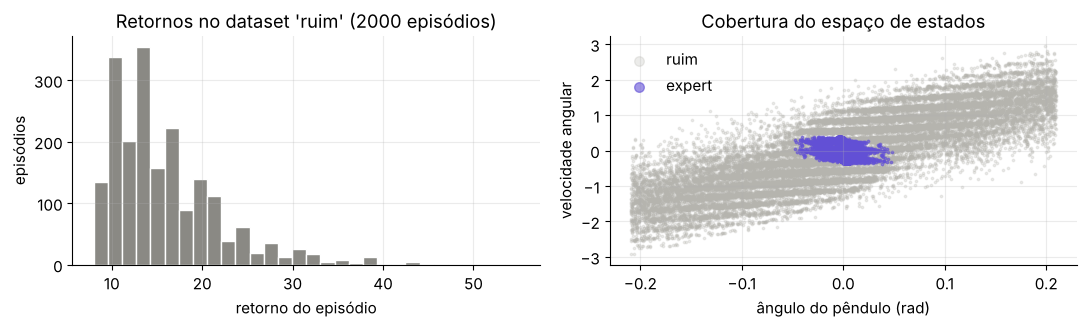

In [4]:
def para_transicoes(dataset):
    # Achata os episódios em tensores (s, a, r, s', done) para treinar.
    S, A, R, S2, D, retornos = [], [], [], [], [], []
    for ep in dataset.iterate_episodes():
        S.append(ep.observations[:-1]); S2.append(ep.observations[1:])
        A.append(ep.actions); R.append(ep.rewards)
        D.append(ep.terminations.astype(np.float32))   # truncation NÃO é terminal: o futuro continua existindo
        retornos.append(ep.rewards.sum())
    f = lambda x: torch.tensor(np.concatenate(x), dtype=torch.float32)
    dados = dict(s=f(S), a=torch.tensor(np.concatenate(A), dtype=torch.long), r=f(R), s2=f(S2), d=f(D))
    return dados, np.array(retornos)

dados_expert, ret_expert = para_transicoes(ds_expert)
dados_ruim,   ret_ruim   = para_transicoes(ds_ruim)

for nome, dados, ret in [("expert", dados_expert, ret_expert), ("ruim", dados_ruim, ret_ruim)]:
    frac_acao1 = dados["a"].float().mean().item()
    print(f"{nome:7s} | {len(dados['a']):6d} transições | retorno médio da política comportamental = {ret.mean():6.1f} ± {ret.std():5.1f}")

fig, axs = plt.subplots(1, 2, figsize=(11, 3.4))
axs[0].hist(ret_ruim, bins=30, color=COR["Comportamental"], edgecolor="white")
axs[0].set_title("Retornos no dataset 'ruim' (2000 episódios)"); axs[0].set_xlabel("retorno do episódio"); axs[0].set_ylabel("episódios")
axs[1].scatter(dados_ruim["s"][:, 2], dados_ruim["s"][:, 3], s=3, alpha=0.25, color="#b5b4ae", label="ruim")
axs[1].scatter(dados_expert["s"][:, 2], dados_expert["s"][:, 3], s=3, alpha=0.6, color="#6250d6", label="expert")
axs[1].set_title("Cobertura do espaço de estados"); axs[1].set_xlabel("ângulo do pêndulo (rad)"); axs[1].set_ylabel("velocidade angular")
axs[1].legend(markerscale=4, frameon=False)
plt.tight_layout(); plt.show()

Repare no gráfico da direita: o dataset **expert** fica concentrado num pequeno núcleo perto do equilíbrio (o especialista nunca deixa o pêndulo cair),
e em cada estado ele sempre tomou *a mesma* ação. O dataset **ruim** se espalha mais e contém as duas ações em quase todo lugar, mas os episódios duram poucos passos.

**Pergunta-chave do Offline RL:** o que dá para aprender com cada um?

## 4. Os três algoritmos

Todos usam a mesma rede (MLP 4 → 256 → 256 → 2) e o mesmo orçamento de passos de gradiente.

**Behavior Cloning:** classificação supervisionada, minimiza $-\log \pi(a \mid s)$ sobre o dataset.

**DQN offline (ingênuo):** Double DQN com rede-alvo, treinado apenas com o dataset:
$$\mathcal{L}_{TD} = \big(Q(s,a) - [r + \gamma (1-d)\, Q_{\text{alvo}}(s', \arg\max_{a'} Q(s',a'))]\big)^2$$

**CQL:** a mesma perda TD **mais** um regularizador conservador:
$$\mathcal{L}_{CQL} = \mathcal{L}_{TD} + \alpha \Big( \underbrace{\log \sum_{a} e^{Q(s,a)}}_{\text{empurra para baixo todas as ações (≈ max)}} - \underbrace{Q(s, a_{\text{dados}})}_{\text{empurra para cima a ação vista}} \Big)$$

O termo *log-sum-exp* é um "máximo suave": ele derruba principalmente a ação de maior valor, e a ação que aparece nos dados é empurrada de volta para cima.
O efeito líquido: ações **não sustentadas pelos dados** ficam com $Q$ baixo, e a política gulosa não se aventura onde não há evidência.
Com $\alpha = 0$, o CQL vira exatamente o DQN offline, o que torna a comparação justa: **a única diferença é o pessimismo**.

In [5]:
def mlp(entrada=4, saida=2, h=256):
    return nn.Sequential(nn.Linear(entrada, h), nn.ReLU(), nn.Linear(h, h), nn.ReLU(), nn.Linear(h, saida))

def treinar_bc(dados, passos=5000, bs=256, seed=0):
    torch.manual_seed(seed)
    net = mlp(); opt = torch.optim.Adam(net.parameters(), 1e-3)
    n = len(dados["a"])
    for _ in range(passos):
        i = torch.randint(n, (bs,))
        perda = F.cross_entropy(net(dados["s"][i]), dados["a"][i])
        opt.zero_grad(); perda.backward(); opt.step()
    return net

def treinar_q(dados, alpha=0.0, passos=15000, bs=256, gamma=GAMMA, seed=0, log_cada=500):
    # alpha = 0 -> DQN offline ingênuo ; alpha > 0 -> CQL (versão discreta)
    torch.manual_seed(seed)
    q, q_alvo = mlp(), mlp(); q_alvo.load_state_dict(q.state_dict())
    opt = torch.optim.Adam(q.parameters(), 3e-4)
    n = len(dados["a"]); s_monitor = dados["s"][:2000]; historico = []
    for t in range(1, passos + 1):
        i = torch.randint(n, (bs,))
        s, a, r, s2, d = (dados[k][i] for k in ("s", "a", "r", "s2", "d"))
        with torch.no_grad():
            a2 = q(s2).argmax(1, keepdim=True)                         # Double DQN
            alvo = r + gamma * (1 - d) * q_alvo(s2).gather(1, a2).squeeze(1)
        q_s = q(s)
        q_sa = q_s.gather(1, a[:, None]).squeeze(1)
        perda = F.mse_loss(q_sa, alvo)
        if alpha > 0:
            perda = perda + alpha * (torch.logsumexp(q_s, dim=1) - q_sa).mean()   # termo conservador
        opt.zero_grad(); perda.backward(); opt.step()
        with torch.no_grad():                                          # atualização suave da rede-alvo
            for p, p_alvo in zip(q.parameters(), q_alvo.parameters()):
                p_alvo.mul_(0.995).add_(0.005 * p)
        if t % log_cada == 0:
            with torch.no_grad():
                historico.append((t, q(s_monitor).max(1).values.mean().item()))
    return q, np.array(historico)

def politica_gulosa(net):
    def pi(obs):
        with torch.no_grad():
            return int(net(torch.tensor(obs, dtype=torch.float32)[None]).argmax())
    return pi

def avaliar(pi, n=30, seed=777):
    # Avaliação ONLINE no simulador (só possível porque é um tutorial; na vida real usaríamos OPE).
    env = gym.make(ENV_ID); rets = []
    for k in range(n):
        obs, _ = env.reset(seed=seed + k); done, R = False, 0.0
        while not done:
            obs, r, term, trunc, _ = env.step(pi(obs)); R += r; done = term or trunc
        rets.append(R)
    return np.array(rets)

## 5. Rodando os experimentos

Para cada dataset treinamos os três métodos com **2 sementes** e avaliamos cada política em 30 episódios novos.
Guardamos também a evolução do valor $\max_a Q(s,a)$ estimado pela rede durante o treino.

> **Um termômetro gratuito:** no CartPole a recompensa é 1 por passo, então o maior valor possível é $\sum_t \gamma^t = \frac{1-\gamma^{500}}{1-\gamma} \approx 99{,}3$.
> **Qualquer $Q$ acima de ~100 é fisicamente impossível**: é a rede acreditando em algo que os dados não sustentam.

(Leva alguns minutos em CPU.)

In [6]:
import time
SEMENTES = [0, 1]
ALPHA_CQL = 1.0
resultados, curvas = {}, {}
t0 = time.time()
for nome_ds, dados in [("expert", dados_expert), ("ruim", dados_ruim)]:
    for metodo in ["BC", "DQN offline", "CQL"]:
        rets, hist = [], []
        for seed in SEMENTES:
            if metodo == "BC":
                net = treinar_bc(dados, seed=seed)
            else:
                net, h = treinar_q(dados, alpha=0.0 if metodo == "DQN offline" else ALPHA_CQL, seed=seed)
                hist.append(h)
            rets.append(avaliar(politica_gulosa(net)))
        resultados[(nome_ds, metodo)] = np.concatenate(rets)
        if hist: curvas[(nome_ds, metodo)] = hist
        print(f"[{time.time()-t0:5.0f}s] {nome_ds:6s} {metodo:12s} retorno = {resultados[(nome_ds, metodo)].mean():6.1f}")

[   36s] expert BC           retorno =  500.0


[  132s] expert DQN offline  retorno =    9.3


[  235s] expert CQL          retorno =  500.0


[  258s] ruim   BC           retorno =    8.8


[  352s] ruim   DQN offline  retorno =  129.1


[  452s] ruim   CQL          retorno =  126.5


## 6. Experimento 1: dados de especialista e o erro de extrapolação

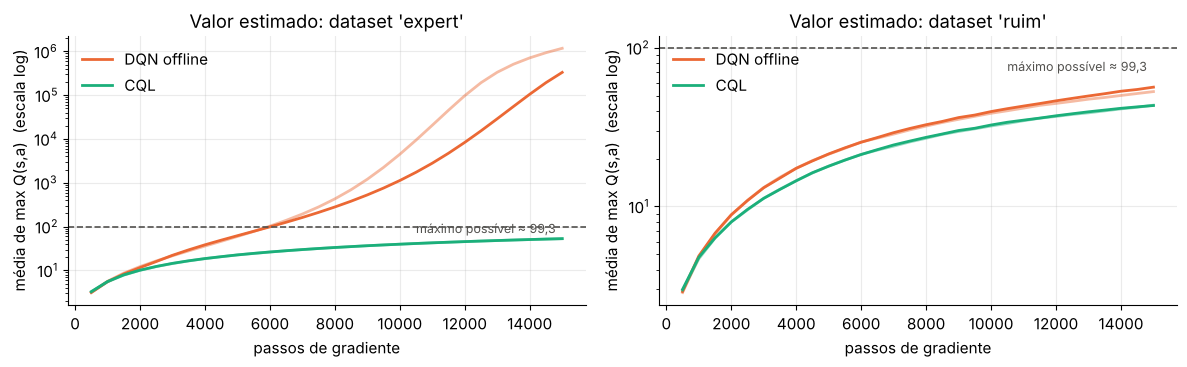

expert | BC           retorno  500.0 ±   0.0
expert | DQN offline  retorno    9.3 ±   0.7
expert | CQL          retorno  500.0 ±   0.0


In [7]:
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, nome_ds in zip(axs, ["expert", "ruim"]):
    for metodo in ["DQN offline", "CQL"]:
        for k, h in enumerate(curvas[(nome_ds, metodo)]):
            ax.plot(h[:, 0], h[:, 1], color=COR[metodo], alpha=1 if k == 0 else 0.45,
                    label=metodo if k == 0 else None)
    ax.axhline(99.3, color="#52514e", ls="--", lw=1.2)
    ax.text(14800, 99.3 * 0.72, "máximo possível ≈ 99,3", color="#52514e", fontsize=9, ha="right")
    ax.set_yscale("log"); ax.set_xlabel("passos de gradiente"); ax.set_ylabel("média de max Q(s,a)  (escala log)")
    ax.set_title(f"Valor estimado: dataset '{nome_ds}'"); ax.legend(frameon=False, loc="upper left")
plt.tight_layout(); plt.show()

for metodo in ["BC", "DQN offline", "CQL"]:
    r = resultados[("expert", metodo)]
    print(f"expert | {metodo:12s} retorno {r.mean():6.1f} ± {r.std():5.1f}")

**O que aconteceu no dataset expert:**

- O especialista **nunca** tomou a ação "errada" em nenhum estado. Logo, o valor dessa ação nunca é corrigido por dado algum: ela é pura extrapolação da rede.
- O DQN offline usa $\max_{a'}$ no alvo. Basta a rede superestimar um pouco a ação nunca vista para o $\max$ escolhê-la, e o bootstrap realimenta o erro. O $Q$ estimado passa de 100 (impossível) e explode por ordens de grandeza.
- A política gulosa então escolhe exatamente as ações superestimadas, que são as ações **que o especialista nunca tomaria**, e o pêndulo cai quase imediatamente.
- O CQL, com o mesmo código e só o termo conservador a mais, mantém $Q$ abaixo do limite físico e reproduz o especialista. O BC também, pois aqui imitar é a resposta certa.

Ou seja: **dados perfeitos não bastam**. Sem cobertura de ações, Q-learning offline ingênuo pode ser *pior* que aleatório. É esse o fenômeno que motivou BCQ, BEAR, CQL e IQL.

## 7. Experimento 2: dados ruins, e superar quem gerou os dados

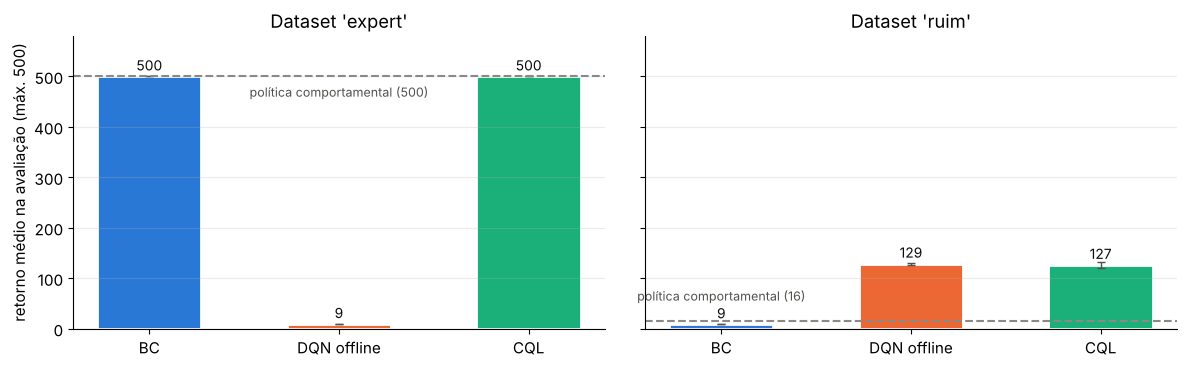

In [8]:
metodos = ["BC", "DQN offline", "CQL"]
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, nome_ds, ret_comp in zip(axs, ["expert", "ruim"], [ret_expert, ret_ruim]):
    medias = [resultados[(nome_ds, m)].mean() for m in metodos]
    erros  = [resultados[(nome_ds, m)].std() / np.sqrt(len(resultados[(nome_ds, m)])) for m in metodos]
    barras = ax.bar(metodos, medias, yerr=erros, color=[COR[m] for m in metodos], width=0.55,
                    edgecolor="white", linewidth=2, capsize=3, error_kw={"ecolor": "#52514e", "lw": 1})
    ax.axhline(ret_comp.mean(), color=COR["Comportamental"], ls="--", lw=1.5)
    alto = ret_comp.mean() > 250
    ax.text(1 if alto else 0, ret_comp.mean() + (-40 if alto else 40), f"política comportamental ({ret_comp.mean():.0f})",
            ha="center", color="#52514e", fontsize=9)
    for b, m in zip(barras, medias):
        ax.text(b.get_x() + b.get_width() / 2, m + 12, f"{m:.0f}", ha="center", fontsize=10, color="#0b0b0b")
    ax.set_ylim(0, 580); ax.set_title(f"Dataset '{nome_ds}'"); ax.grid(axis="x", visible=False)
axs[0].set_ylabel("retorno médio na avaliação (máx. 500)")
plt.tight_layout(); plt.show()

**O que aconteceu no dataset ruim:**

- A política comportamental escolhe a ação errada na maioria das vezes. O BC aprende fielmente **a ação mais frequente em cada estado**, ou seja, a errada: fica até pior que os dados.
- O Offline RL não pergunta "o que foi feito?", e sim "**o que deu certo?**". Como as duas ações aparecem em quase todos os estados, a recompensa e a duração dos episódios bastam para o Q-learning descobrir qual ação mantém o pêndulo em pé, e a política extraída **supera em muito quem gerou os dados**.
- O retorno não chega a 500: os dados só mostram episódios de 10 a 40 passos, e generalizar para horizontes 10× maiores é extrapolação. Mais dados, mais passos de treino (repare que $Q$ ainda está subindo) ou dados mais diversos elevariam esse número.
- Aqui o DQN offline não diverge: com cobertura das duas ações, não há ação OOD para ser superestimada. O pessimismo do CQL custa pouco e mantém as estimativas abaixo do limite físico.

Esse é o argumento central a favor do Offline RL: **com dados diversos, dá para aprender políticas melhores que a média dos dados**, coisa que nenhuma imitação faz.

## 8. Score normalizado com o Minari

Como registramos `ref_min_score` e `ref_max_score` ao criar os datasets, o Minari calcula o **score normalizado** (0 = referência ruim, 1 = especialista), o mesmo usado nos artigos com D4RL:

In [9]:
print(f"{'dataset':8s} {'método':13s} {'retorno':>8s} {'normalizado':>12s}")
for nome_ds, d in [("expert", ds_expert), ("ruim", ds_ruim)]:
    ret_c = (ret_expert if nome_ds == "expert" else ret_ruim).mean()
    print(f"{nome_ds:8s} {'(comportam.)':13s} {ret_c:8.1f} {float(minari.get_normalized_score(d, np.array([ret_c]))[0]):12.2f}")
    for m in metodos:
        r = resultados[(nome_ds, m)].mean()
        print(f"{nome_ds:8s} {m:13s} {r:8.1f} {float(minari.get_normalized_score(d, np.array([r]))[0]):12.2f}")

dataset  método         retorno  normalizado
expert   (comportam.)     500.0         1.00
expert   BC               500.0         1.00
expert   DQN offline        9.3        -0.00
expert   CQL              500.0         1.00
ruim     (comportam.)      15.9         0.01
ruim     BC                 8.8        -0.00
ruim     DQN offline      129.1         0.24
ruim     CQL              126.5         0.24


## 9. Lições e próximos passos

**Resumo do que vimos**

| | Dataset expert (sem cobertura) | Dataset ruim (com cobertura) |
|---|---|---|
| **BC** | ✅ imita o especialista | ❌ imita o erro |
| **DQN offline** | ❌ diverge (erro de extrapolação) | ✅ supera os dados |
| **CQL** | ✅ pessimismo evita a divergência | ✅ supera os dados |

1. **Rode BC primeiro.** Se os dados são bons e homogêneos, ele é difícil de bater.
2. **Offline RL brilha com dados diversos e subótimos**: ele seleciona o que funcionou e pode "costurar" bons trechos de trajetórias diferentes.
3. **Q-learning ingênuo é perigoso offline.** Monitore a magnitude de $Q$ contra um limite plausível; divergência silenciosa é o modo de falha mais comum.
4. **Pessimismo / restrição à distribuição dos dados** (CQL, IQL, TD3+BC) é o que torna o método seguro.
5. **Avaliação é o calcanhar de Aquiles.** Aqui avaliamos no simulador. Num problema real isso não existe, e você precisa de *Off-Policy Evaluation* (FQE, importance sampling, doubly robust) para escolher hiperparâmetros como $\alpha$.

**Para continuar:**
- Datasets prontos: `minari.list_remote_datasets()` e `minari.load_dataset("mujoco/halfcheetah/medium-v0", download=True)` (ações contínuas, benchmark D4RL).
- Implementações robustas: **d3rlpy** e **CORL** (CQL, IQL, TD3+BC, Decision Transformer), ambos com suporte a Minari.
- Experimentos sugeridos neste notebook: varie `ALPHA_CQL` (0, 0.1, 1, 5), misture os dois datasets com `minari.combine_datasets`, ou reduza o número de episódios para ver como cada método reage a menos dados.